In [25]:
import numpy as np
import matplotlib.pyplot as plt
import os

$$
\begin{aligned}
\frac{dS}{dt} &= \mu N - \beta S I - \mu S, \\
\frac{dE}{dt} &= \beta S I - (\sigma + \mu) E, \\
\frac{dI}{dt} &= \sigma E - (\gamma + \mu) I, \\
\frac{dR}{dt} &= \gamma I - \mu R,
\end{aligned}
$$

where $E$ is the exposed (infected but not yet infectious) population, $\sigma$ is the rate of becoming infectious ($1/\sigma$ is the mean latent period), and $\mu$ is the birth and death rate.

In [26]:
def seir_modeling(t, y, beta, gamma, sigma, mu, N=2000):
    S, E, I, R = y
    dSdt = mu*N - beta*S*I - mu*S
    dEdt = beta*S*I - (sigma + mu)*E
    dIdt = sigma*E - (gamma + mu)*I
    dRdt = gamma*I - mu*R

    return np.array([dSdt, dEdt, dIdt, dRdt])

def seir_runge_kutta(f, y, t, beta, gamma, sigma, mu, N=2000):
    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        k1 = f(t[i-1], y[i-1], beta, gamma, sigma, mu, N)
        k2 = f(t[i-1] + dt/2, y[i-1] + dt/2 * k1, beta, gamma, sigma, mu, N)
        k3 = f(t[i-1] + dt/2, y[i-1] + dt/2 * k2, beta, gamma, sigma, mu, N)
        k4 = f(t[i-1] + dt, y[i-1] + dt * k3, beta, gamma, sigma, mu, N)
        y[i] = y[i-1] + dt/6 * (k1 + 2*k2 + 2*k3 + k4)
    return t, y

# Use runge_kutta to solve the SEIR model
def seir_solver(f, y0, days, dt, beta, gamma, sigma, mu, N=2000):
    t = np.arange(0, days + dt, dt)
    y = np.zeros((len(t), len(y0)))
    y[0] = y0
    t, y = seir_runge_kutta(f, y, t, beta, gamma, sigma, mu, N)
    return t, y

In [27]:
# Constants for SEIR model
N = 2000
y0 = [1980, 15, 5, 0]
beta = 0.125*1e-3
gamma = 0.1
sigma = 0.25
mu = 0.005
dt = 0.1
# first setting for simulation
days = 365

In [28]:
t, y = seir_solver(seir_modeling, y0, days, dt, beta=beta, gamma=gamma, sigma=sigma, mu=mu)

S = y[:, 0]
E = y[:, 1]
I = y[:, 2]
R = y[:, 3]

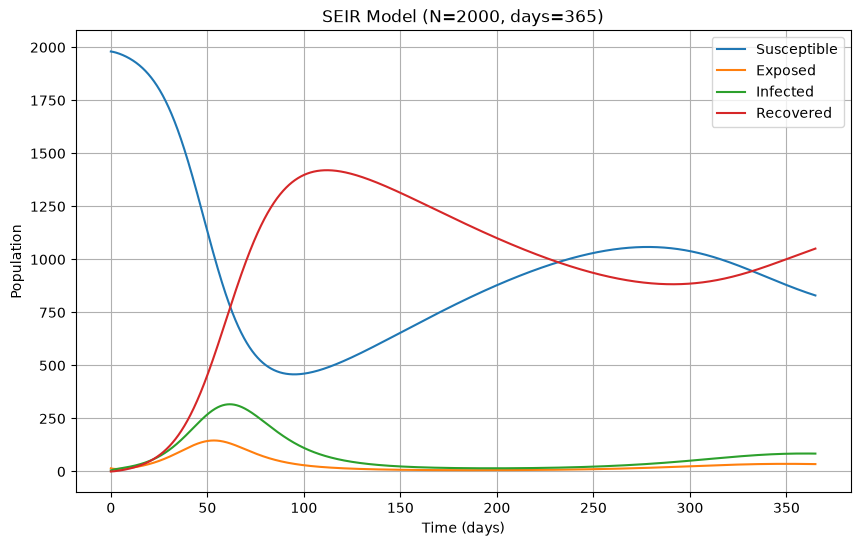

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, S, label="Susceptible")
ax.plot(t, E, label="Exposed")
ax.plot(t, I, label="Infected")
ax.plot(t, R, label="Recovered")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Population")
ax.set_title("SEIR Model (N=2000, days=365)")
ax.legend()
ax.grid()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/seir_model_365days.png")

plt.show()

In [30]:
# Find the timing and size of each epidemic wave
from scipy.signal import find_peaks
peaks, _ = find_peaks(I)
peak_times = t[peaks]
peak_sizes = I[peaks]
print("Peak times:", peak_times)
print("Peak sizes:", peak_sizes)

Peak times: [ 61.6 359.2]
Peak sizes: [316.92040355  84.75988324]


In [31]:
days = 1500
t, y = seir_solver(seir_modeling, y0, days, dt, beta=beta, gamma=gamma, sigma=sigma, mu=mu)

S = y[:, 0]
E = y[:, 1]
I = y[:, 2]
R = y[:, 3]

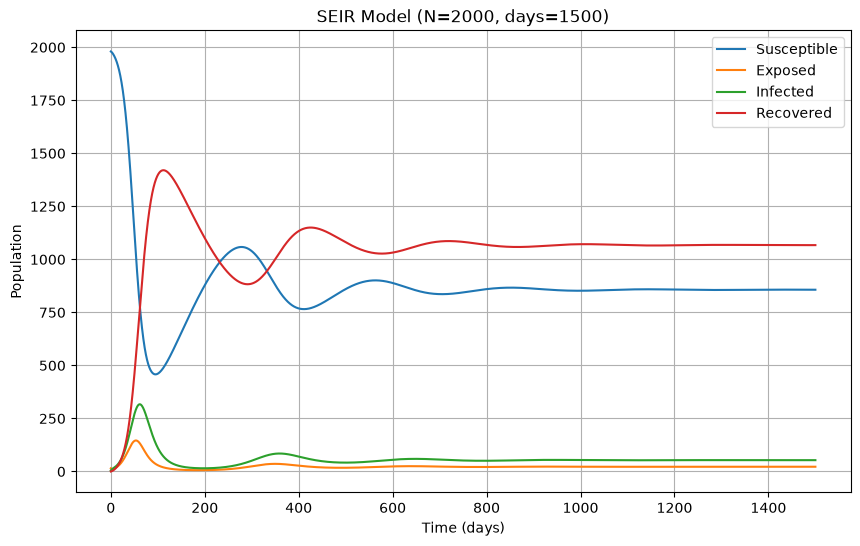

In [32]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, S, label="Susceptible")
ax.plot(t, E, label="Exposed")
ax.plot(t, I, label="Infected")
ax.plot(t, R, label="Recovered")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Population")
ax.set_title("SEIR Model (N=2000, days=1500)")
ax.legend()
ax.grid()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/seir_model_1500days.png")

plt.show()

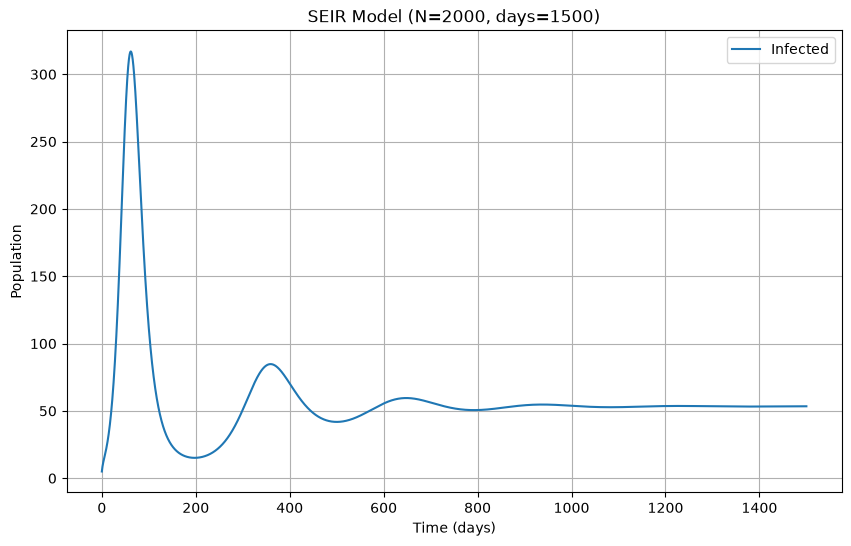

In [33]:
# Plot only I curve for iii 
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, I, label="Infected")  # Plot only the I curve for iii
ax.set_xlabel("Time (days)")
ax.set_ylabel("Population")
ax.set_title("SEIR Model (N=2000, days=1500)")
ax.legend()
ax.grid()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/seir_model_1500days_I_curve.png")

plt.show()

In [34]:
# Find the timing and size of each epidemic wave
peaks, _ = find_peaks(I)
peak_times = t[peaks]
peak_sizes = I[peaks]
print("Peak times:", peak_times)
print("Peak sizes:", peak_sizes)

Peak times: [  61.6  359.2  648.1  938.  1228.3]
Peak sizes: [316.92040355  84.75988324  59.55957028  54.72418447  53.67370837]


In [35]:
# problem iv
R0 = beta*N*sigma / ((sigma + mu)*(gamma + mu))
print("Basic reproduction number R0:", R0)

Basic reproduction number R0: 2.334267040149393


In [37]:
print(f"Long-term S: {S[-1]}")
print(f"N/R0 = {N/R0}")

Long-term S: 856.9233583170079
N/R0 = 856.8000000000001
